In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import openpyxl
from scipy.stats import norm

In [2]:
# BẢNG SỐ LIỆU FIT VỪA KHUNG CODE / NOTEBOOK – KHÔNG CẦN CUỘN TRONG BẢNG
# Chỉ thay đổi cách trình bày, không thay dữ liệu, công thức hay các biểu đồ.
from IPython.display import HTML, display
from html import escape
import pandas as pd


def hien_thi_bang(du_lieu, tieu_de, ghi_chu="", dinh_dang=None, chieu_cao=None):
    """Bảng tự co vừa khung notebook, không có thanh cuộn dọc/ngang riêng.

    chieu_cao giữ lại để tương thích các lệnh gọi cũ, nhưng không còn giới hạn
    chiều cao bảng: toàn bộ hàng được hiển thị ngay dưới cell code.
    """
    bang = du_lieu.copy().reset_index(drop=True)
    dinh_dang = dinh_dang or {}
    so_cot = len(bang.columns)
    if so_cot == 0:
        display(HTML("<p>Không có cột dữ liệu để hiển thị.</p>"))
        return

    def dinh_dang_o(gia_tri, ten_cot):
        if pd.isna(gia_tri):
            return "—"
        mau = dinh_dang.get(ten_cot)
        if mau:
            try:
                return str(mau.format(gia_tri))
            except (ValueError, TypeError):
                pass
        return str(gia_tri)

    # Giữ nội dung trong phạm vi độ rộng ô Output. Không set min-width, không overflow:auto.
    css = """
      <style>
      .bang-fit-wrap {box-sizing:border-box!important;width:100%!important;max-width:100%!important;
         margin:12px 0 20px;padding:12px 12px 8px;border:1px solid #dce5ef;
         border-radius:10px;background:#fff;color:#1b354f;font-family:Arial,sans-serif;
         overflow:visible!important;}
      .bang-fit-top {display:flex;align-items:center;justify-content:space-between;
         flex-wrap:wrap;gap:7px;margin-bottom:7px;}
      .bang-fit-title {font-size:16px;font-weight:700;line-height:1.4;min-width:0;}
      .bang-fit-count {font-size:12px;font-weight:600;white-space:nowrap;
         color:#096d74;background:#e2f4f4;border-radius:20px;padding:4px 9px;}
      .bang-fit-note {font-size:12px;line-height:1.5;color:#516983;
         margin-bottom:9px;overflow-wrap:anywhere;}
      table.bang-fit-table {border-collapse:collapse!important;border-spacing:0!important;
         table-layout:fixed!important;width:100%!important;max-width:100%!important;
         min-width:0!important;margin:0!important;font-family:Arial,sans-serif;
         font-size:13px!important;border:1px solid #cfdeeb;}
      table.bang-fit-table thead th {box-sizing:border-box!important;text-align:center!important;
         padding:9px 5px!important;background:#173f69!important;color:#fff!important;
         font-weight:700!important;line-height:1.35!important;
         border:1px solid #3e668e!important;white-space:normal!important;
         overflow-wrap:break-word!important;word-break:normal!important;}
      table.bang-fit-table tbody td {box-sizing:border-box!important;text-align:center!important;
         padding:6px 4px!important;line-height:1.35!important;
         color:#203a55!important;border:1px solid #dfe8f0!important;
         font-variant-numeric:tabular-nums!important;white-space:normal!important;
         overflow-wrap:anywhere!important;}
      table.bang-fit-table tbody tr:nth-child(even) td {background:#f0f6fb!important;}
      table.bang-fit-table tbody tr:nth-child(odd) td {background:#fff!important;}
      table.bang-fit-table tbody tr:hover td {background:#dbf3ed!important;}
      @media (max-width: 650px) {
         .bang-fit-wrap {padding:8px 5px 5px!important;}
         .bang-fit-title {font-size:14px!important;}
         .bang-fit-note {font-size:11px!important;}
         table.bang-fit-table {font-size:11px!important;}
         table.bang-fit-table thead th {padding:7px 2px!important;}
         table.bang-fit-table tbody td {padding:5px 2px!important;}
      }
      </style>
    """
    widths = (["18%", "82%"] if so_cot == 2 else
              ["17%", "28%", "27%", "28%"] if so_cot == 4 else
              [f"{100 / so_cot:.4f}%"] * so_cot)
    headers = "".join(f'<th scope="col" style="width:{widths[i]}">{escape(str(col))}</th>'
                      for i, col in enumerate(bang.columns))
    rows = []
    for k, values in enumerate(bang.itertuples(index=False, name=None)):
        cells = "".join(
            f'<td>{escape(dinh_dang_o(value, col))}</td>'
            for col, value in zip(bang.columns, values)
        )
        rows.append(f'<tr>{cells}</tr>')
    note = f'<div class="bang-fit-note">{escape(ghi_chu)}</div>' if ghi_chu else ""
    output = (
        css + '<div class="bang-fit-wrap">'
        + '<div class="bang-fit-top">'
        + f'<div class="bang-fit-title">{escape(tieu_de)}</div>'
        + f'<span class="bang-fit-count">{len(bang)} quan sát</span>'
        + '</div>' + note
        + '<table class="bang-fit-table"><colgroup>'
        + "".join(f'<col style="width:{x}">' for x in widths)
        + '</colgroup><thead><tr>' + headers + '</tr></thead><tbody>'
        + "".join(rows)
        + '</tbody></table>'
        + '</div>'
    )
    display(HTML(output))


def hien_thi_bang_qq(bang_qq, tieu_de, so_le_x=2):
    """Bảng Q–Q bốn cột gọn; giải thích ký hiệu ở dòng ghi chú phía trên."""
    bang_ro = bang_qq.rename(columns={
        "j": "STT (j)",
        "x_j": "Giá trị (xⱼ)",
        "(j - 0,5)/n": "Xác suất (pⱼ)",
        "z_j = Φ⁻¹((j - 0,5)/n)": "Phân vị (zⱼ)",
    })
    hien_thi_bang(
        bang_ro,
        tieu_de=tieu_de,
        ghi_chu="xⱼ: số liệu tăng dần; pⱼ = (j − 0,5)/n; zⱼ = Φ⁻¹(pⱼ). Bảng tự vừa khung, hiển thị đủ tất cả các hàng.",
        dinh_dang={
            "STT (j)": "{:.0f}",
            "Giá trị (xⱼ)": "{:." + str(so_le_x) + "f}",
            "Xác suất (pⱼ)": "{:.3f}",
            "Phân vị (zⱼ)": "{:+.3f}",
        },
    )


In [3]:
data = pd.read_excel('Data/Book1.xlsx')
x = data['J ']
X_j = data['Xj']

# Bảng số liệu ban đầu gọn gàng (thay cho việc in từng dòng bằng print).
bang_ban_dau = pd.DataFrame({
    'Thứ tự (j)': x.to_numpy(),
    'Giá trị Xⱼ': X_j.to_numpy()
})
hien_thi_bang(
    bang_ban_dau,
    'BẢNG SỐ LIỆU BAN ĐẦU – VÍ DỤ 4.7',
    ghi_chu='Dữ liệu đọc trực tiếp từ tệp Data/Book1.xlsx.',
    dinh_dang={'Thứ tự (j)': '{:.0f}', 'Giá trị Xⱼ': '{:.0f}'},
    chieu_cao=380
)


Thứ tự (j),Giá trị Xⱼ
1,176
2,183
3,185
4,190
5,191
6,192
7,201
8,205
9,214
10,220


STT (j),Giá trị (xⱼ),Xác suất (pⱼ),Phân vị (zⱼ)
1,176,0.050,-1.645
2,183,0.150,-1.036
3,185,0.250,-0.674
4,190,0.350,-0.385
5,191,0.450,-0.126
6,192,0.550,+0.126
7,201,0.650,+0.385
8,205,0.750,+0.674
9,214,0.850,+1.036
10,220,0.950,+1.645


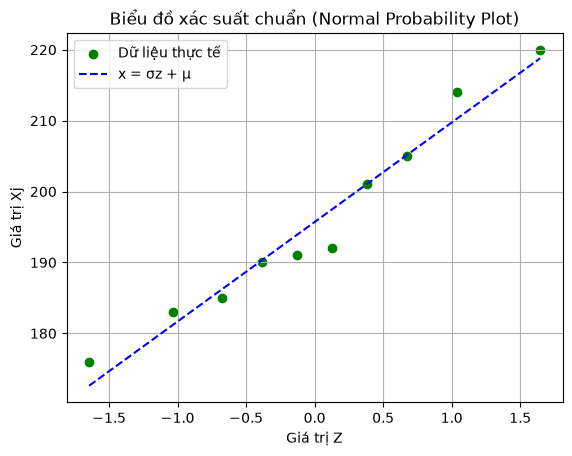

In [4]:

X_j = np.sort(data['Xj'])  # sắp xếp tăng dần

# Tính n, t, z
n = len(X_j)
t = [(i - 0.5)/n for i in range(1, n+1)]
z = norm.ppf(t)

# Tính các tham số μ và σ
mu = np.mean(X_j)
sigma = np.std(X_j, ddof=1)

# BẢNG SỐ LIỆU TRƯỚC BIỂU ĐỒ Q-Q (theo bảng Ví dụ 4.7 của giáo trình)
bang_qq = pd.DataFrame({
    'j': np.arange(1, n + 1),
    'x_j': X_j,
    '(j - 0,5)/n': t,
    'z_j = Φ⁻¹((j - 0,5)/n)': z
})
hien_thi_bang_qq(bang_qq, 'BẢNG PHÂN VỊ CHUẨN – VÍ DỤ 4.7', so_le_x=0)

# Vẽ các điểm dữ liệu
plt.scatter(z, X_j, color='green', label='Dữ liệu thực tế')

# Vẽ đường x = σz + μ
x_line = sigma * np.array(z) + mu
plt.plot(z, x_line, color='blue', linestyle='--', label='x = σz + μ')

# Trang trí
plt.title("Biểu đồ xác suất chuẩn (Normal Probability Plot)")
plt.xlabel("Giá trị Z")
plt.ylabel("Giá trị Xj")
plt.legend()
plt.grid(True)
plt.show()


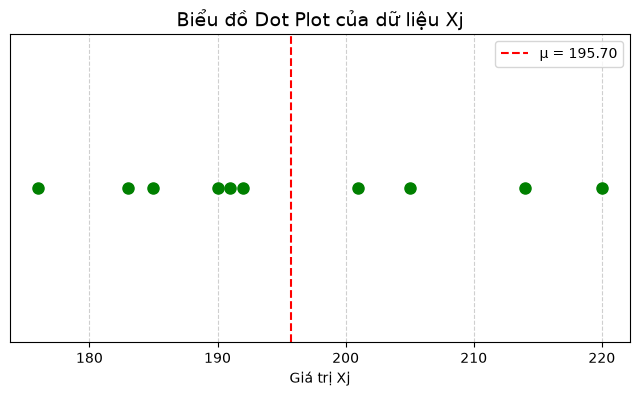

In [5]:
# --- Biểu đồ Dot Plot ---
plt.figure(figsize=(8, 4))
plt.plot(X_j, [1]*len(X_j), 'go', markersize=8)  # ‘go’ = chấm tròn màu xanh

plt.yticks([])  # Ẩn trục Y (vì dot plot 1 chiều)
plt.title("Biểu đồ Dot Plot của dữ liệu Xj", fontsize=14)
plt.xlabel("Giá trị Xj")
plt.grid(axis='x', linestyle='--', alpha=0.6)

# Thêm đường thể hiện giá trị trung bình
plt.axvline(mu, color='red', linestyle='--', label=f"μ = {mu:.2f}")
plt.legend()
plt.show()

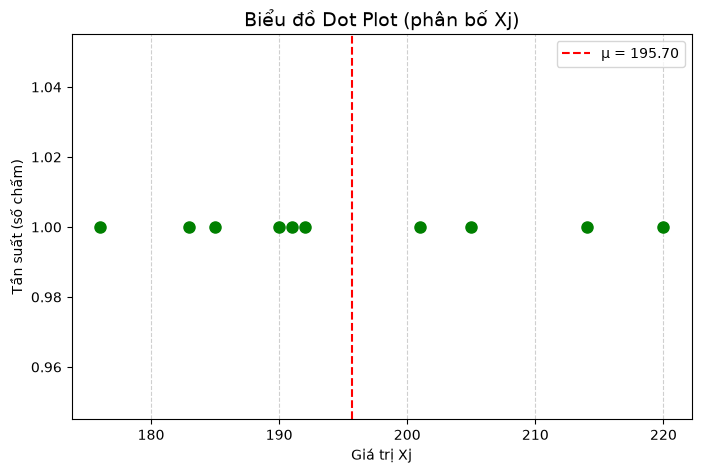

In [6]:
unique_vals, counts = np.unique(X_j, return_counts=True)

plt.figure(figsize=(8,5))
for x, count in zip(unique_vals, counts):
    plt.plot([x]*count, np.arange(1, count+1), 'go', markersize=8)

plt.title("Biểu đồ Dot Plot (phân bố Xj)", fontsize=14)
plt.xlabel("Giá trị Xj")
plt.ylabel("Tần suất (số chấm)")
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.axvline(mu, color='red', linestyle='--', label=f"μ = {mu:.2f}")
plt.legend()
plt.show()
